# Core results: optimized charging vs baselines

**Question:** how much can scheduling lower a workplace charging site's peak power, while every car still gets the energy it actually received?

**Setup.** JPL site, pre-COVID weekdays (2019-01-01 → 2020-02-29), 15-minute slots, 03:00–03:00 operational days. Energy target per car = `kWhDelivered`. Every car can draw up to 6.656 kW.

| Method | What it does | Knows the future? |
|---|---|---|
| **Optimized (LP)** | Minimizes the day's peak; every car gets its energy before leaving | Yes: actual departures (perfect information) |
| **Uncontrolled** | Every car charges at full speed from plug-in until done | No |
| **Equal sharing** | A site cap is split equally among cars still charging | No |

Colors are the same in every figure: **blue = LP**, **orange = uncontrolled**, **aqua = equal sharing**.
See `PROJECT_GUIDE.md` for the model and every modelling decision.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from acn import analysis, plots
from acn.run_core import run

plots.style()
pd.set_option("display.precision", 1)

SITE, START, END = "jpl", "2019-01-01", "2020-02-29"
MIN_SESSIONS = 5   # ignore near-empty days (holidays) in summaries
FIGS = ROOT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

## 1. Run (or load) the core experiment

In [2]:
csv = ROOT / "results" / f"core_{SITE}_daily_{START}_{END}.csv"
res_all = pd.read_csv(csv) if csv.exists() else run(SITE, START, END)
res_all["date"] = pd.to_datetime(res_all["date"]).dt.date
res = res_all[res_all["weekday"].isin(plots.WEEKDAYS) & (res_all["n_sessions"] >= MIN_SESSIONS)].reset_index(drop=True)
print(f"{len(res_all)} days run; {len(res)} weekdays with >= {MIN_SESSIONS} sessions used below")
print(f"LP feasibility violations: {int(res_all['lp_violations'].sum())}, "
      f"LP unmet energy: {res_all['lp_unmet_kwh'].sum():.4f} kWh")

420 days run; 297 weekdays with >= 5 sessions used below
LP feasibility violations: 0, LP unmet energy: 0.0000 kWh


## 2. A fair comparison: what peak does each method need to deliver 100% of energy?

The LP and uncontrolled charging both deliver all energy by construction. For equal sharing, we search (by bisection) for the **smallest site cap at which it also delivers everything**. Then all three are compared on the one thing that differs: the peak.

In [3]:
instances = analysis.load_day_instances(SITE, START, END, MIN_SESSIONS)
instances = {d: instances[d] for d in res["date"] if d in instances}
res["peak_equal_share_min_kw"] = [
    analysis.min_cap_equal_share(instances[d], hi=u + 1e-6)
    for d, u in zip(res["date"], res["peak_uncontrolled_kw"])]

summary = pd.DataFrame({
    "median daily peak (kW)": [res[c].median() for c in ["peak_uncontrolled_kw", "peak_equal_share_min_kw", "peak_lp_kw"]],
    "mean daily peak (kW)": [res[c].mean() for c in ["peak_uncontrolled_kw", "peak_equal_share_min_kw", "peak_lp_kw"]],
    "highest daily peak (kW)": [res[c].max() for c in ["peak_uncontrolled_kw", "peak_equal_share_min_kw", "peak_lp_kw"]],
}, index=[plots.LABELS[k] for k in ["uncontrolled", "equal_share", "lp"]])
summary["median reduction vs uncontrolled"] = [
    f"{(1 - res[c] / res['peak_uncontrolled_kw']).median():.0%}"
    for c in ["peak_uncontrolled_kw", "peak_equal_share_min_kw", "peak_lp_kw"]]
display(summary)

,median daily peak (kW),mean daily peak (kW),highest daily peak (kW),median reduction vs uncontrolled
Uncontrolled,254.4,230.3,313.4,0%
Equal sharing,144.0,136.7,261.0,40%
Optimized (LP),80.9,76.0,107.9,67%


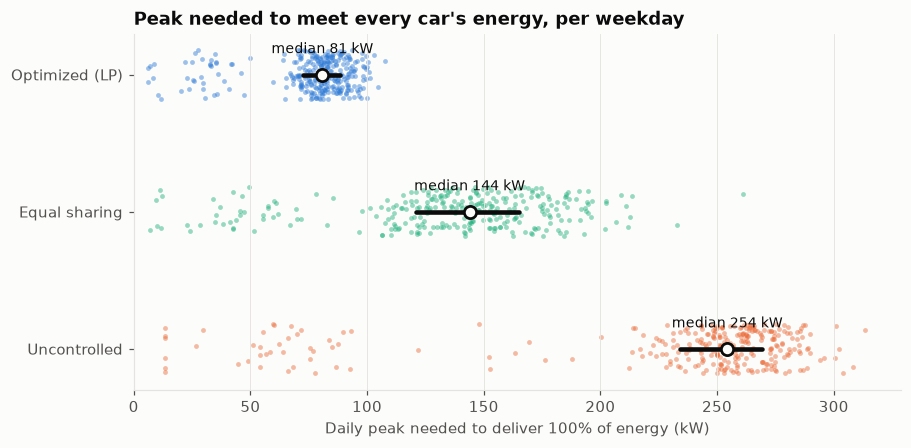

In [4]:
fig = plots.peak_distributions(res, res["peak_equal_share_min_kw"])
save(fig, "peak_distributions")

## 3. One typical day, up close

The day shown is the weekday whose peak reduction is closest to the median, so it is a typical day, not a cherry-picked one.

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
2019-09-23 (Monday): 79 sessions, 1082 kWh delivered


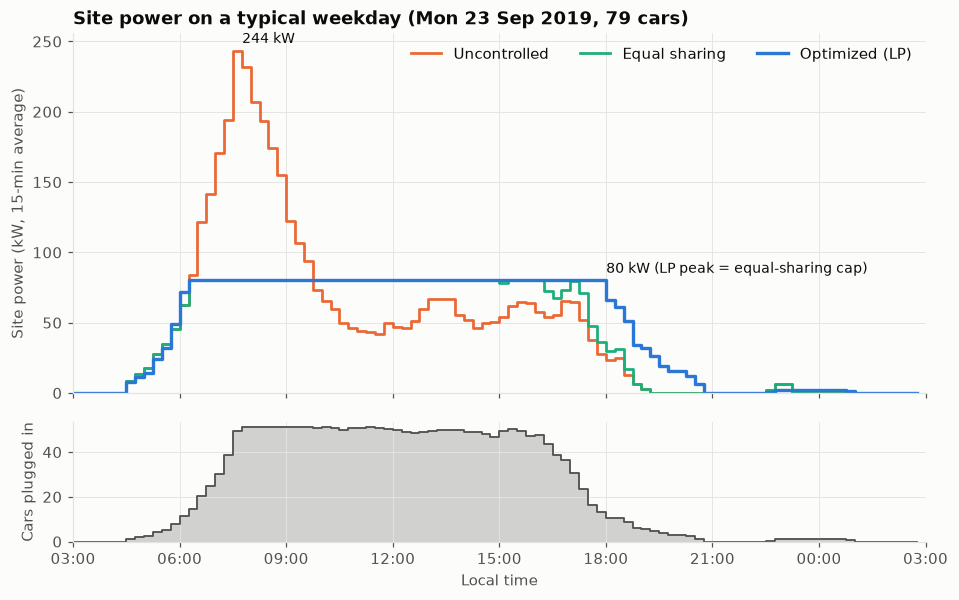

In [5]:
typical = res.iloc[(res["peak_reduction"] - res["peak_reduction"].median()).abs().argmin()]
day = typical["date"]
inst = instances[day]
sched = analysis.day_schedules(inst)
print(f"{day} ({typical['weekday']}): {inst.n} sessions, {inst.energy.sum():.0f} kWh delivered")
fig = plots.day_profile(inst, sched, analysis.occupancy(inst),
                        f"Site power on a typical weekday ({day:%a %d %b %Y}, {inst.n} cars)")
save(fig, "typical_day_profile")

**How to read it.**
- Uncontrolled charging spikes when everyone arrives (around 7–8 am), then collapses as cars finish.
- The LP spreads the same energy across the hours the cars are parked, so the line is flat.
- Equal sharing here is capped at the LP's peak, so it has the same flat top. It doesn't know when cars leave, though, so some leave short (section 5).

The bottom panel shows why the LP has room to work: most cars stay plugged in for 7–9 hours.

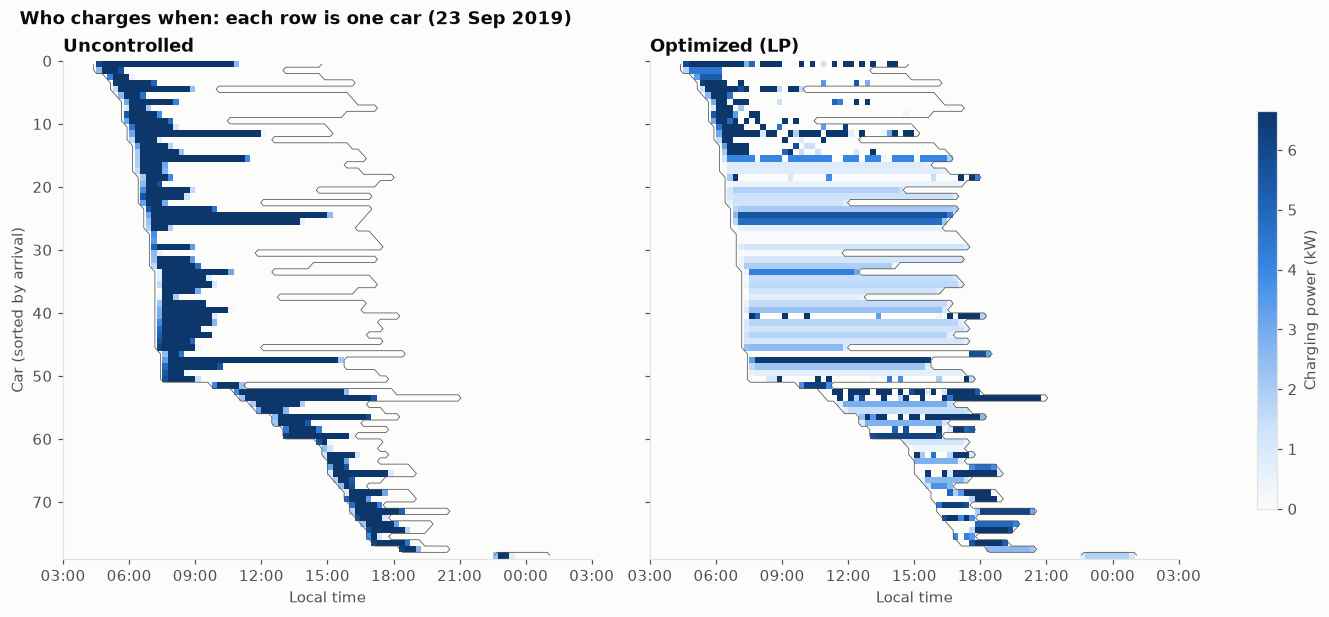

In [6]:
fig = plots.schedule_heatmaps(inst, sched, f"Who charges when: each row is one car ({day:%d %b %Y})")
save(fig, "typical_day_heatmaps")

Each row is one car, and the grey outline is when it's plugged in. Uncontrolled charging is a dark block at the left edge of every row (full power right away). The LP spreads charging across each car's whole stay and fills the midday gap.

**About the LP schedule shown:** the peak LP fixes only the *peak*. Many schedules reach the same 80 kW, and a plain solver returns an arbitrary corner solution that toggles cars on and off. This figure uses `min_peak(..., smooth=True)`: a second LP that keeps the peak fixed and minimizes each car's highest charging power, so cars charge as evenly as the peak allows. The peak is identical; only the choice among optimal schedules changes.

## 4. Every weekday, over 14 months

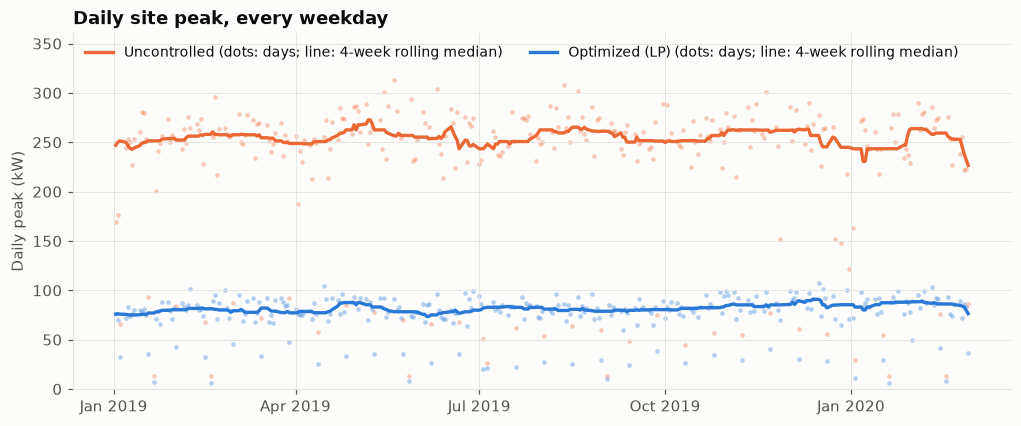

In [7]:
fig = plots.peaks_over_time(res)
save(fig, "peaks_over_time")

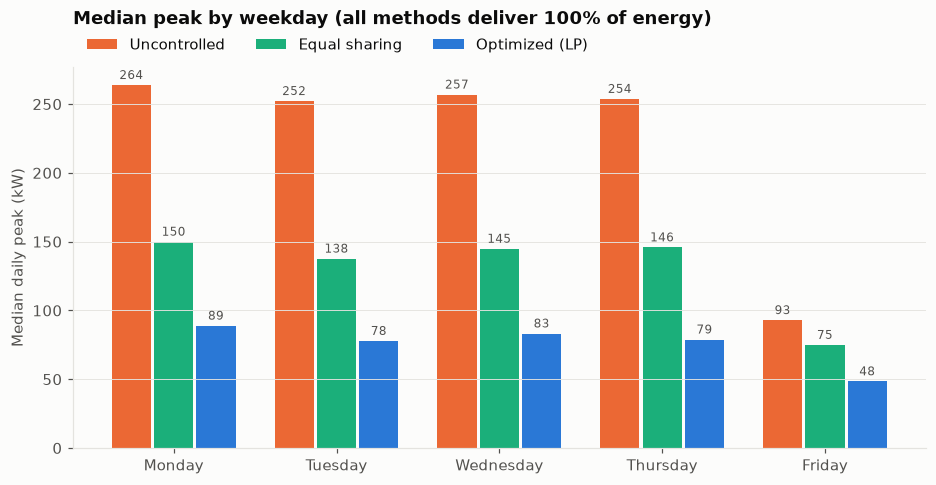

In [8]:
fig = plots.by_weekday(res)
save(fig, "peaks_by_weekday")

**Fridays are different.** About every other Friday is much quieter (25–45 sessions instead of about 70), which shows as the two clusters in the next figure and the low Friday medians here. That fits a 9/80 schedule (alternate Fridays off), which I believe JPL uses but haven't verified. Analyze busy days and quiet Fridays separately, or say that the Friday median mixes two kinds of day.

Correlation (sessions, reduction): 0.75


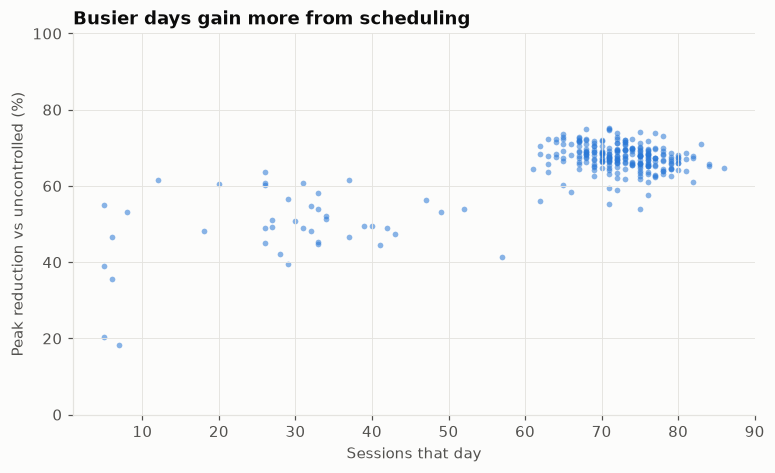

In [9]:
fig = plots.reduction_vs_sessions(res)
save(fig, "reduction_vs_sessions")
print(f"Correlation (sessions, reduction): {res[['n_sessions', 'peak_reduction']].corr().iloc[0, 1]:.2f}")

## 5. Same cap, different outcome: unmet energy under equal sharing

Fix the site cap and ask how much energy each method fails to deliver. At a cap equal to the LP's optimal peak (1.0×), the LP delivers everything by construction. Equal sharing shares fairly but doesn't plan, so cars that leave early go home short. Raising the cap reduces unmet energy, and the curve shows how far it has to rise.

multiplier,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0,2.2,2.5,3.0
median_unmet_pct,8.6,4.8,2.6,1.5,0.8,0.4,0.2,3.0e-02,0.0,0.0,0.0,0.0,0.0,0.0
p90_unmet_pct,11.7,7.5,4.7,3.0,2.1,1.4,1.0,7.0e-01,0.5,0.3,0.2,0.0,0.0,0.0
days_with_any_unmet_pct,100.0,99.7,98.7,96.3,90.6,77.1,66.7,5.3e+01,41.4,31.6,24.2,10.1,3.0,0.0


Non-monotone steps across all days: 0


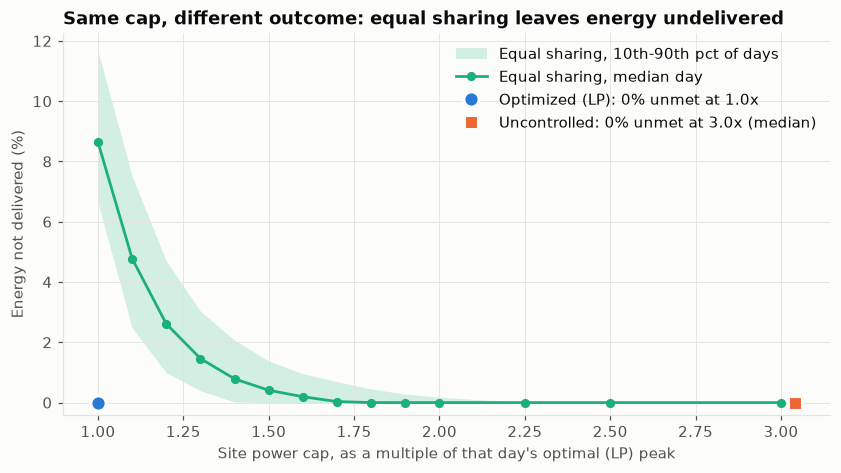

In [10]:
mult = np.round(np.r_[np.arange(1.0, 2.01, 0.1), 2.25, 2.5, 3.0], 2)
sweep = analysis.cap_sweep(instances, dict(zip(res["date"], res["peak_lp_kw"])), mult)
fig = plots.tradeoff(sweep, res)
save(fig, "tradeoff_cap_vs_unmet")

tbl = sweep.groupby("multiplier").agg(
    median_unmet_pct=("unmet_frac", lambda s: 100 * s.median()),
    p90_unmet_pct=("unmet_frac", lambda s: 100 * s.quantile(0.9)),
    days_with_any_unmet_pct=("unmet_kwh", lambda s: 100 * (s > analysis.UNMET_TOL_KWH).mean()))
display(tbl.T.round(2))

# Sanity: is unmet energy non-increasing in the cap on every day? (bisection above assumes it)
viol = sweep.sort_values(["date", "multiplier"]).groupby("date")["unmet_kwh"].apply(
    lambda s: (s.diff() > 1e-6).sum()).sum()
print(f"Non-monotone steps across all days: {viol}")

## 6. Does the planning horizon matter? Daily vs weekly models

In [11]:
rows = {}
for tag in ["daily", "weekly_daily", "weekly_max"]:
    f = ROOT / "results" / f"core_{SITE}_{tag}_{START}_{END}.csv"
    if not f.exists():
        continue
    r = pd.read_csv(f)
    r = r[r["weekday"].isin(plots.WEEKDAYS) & (r["n_sessions"] >= MIN_SESSIONS)]
    rows[tag] = {"weekdays": len(r), "median LP peak (kW)": r["peak_lp_kw"].median(),
                 "median reduction": f"{r['peak_reduction'].median():.1%}",
                 "sessions dropped at boundary": int(r["n_dropped_boundary"].sum())}
display(pd.DataFrame(rows).T)

,weekdays,median LP peak (kW),median reduction,sessions dropped at boundary
daily,297,80.9,67.1%,40
weekly_daily,289,80.9,67.2%,3
weekly_max,289,80.9,67.2%,3


At JPL the three variants agree. Almost no session crosses the 03:00 boundary, so the weekly model splits into independent days. The weekly versions matter for Caltech (about 4% overnight sessions) and once prices link the days.

## 7. Caveats: read before quoting a number

1. **Perfect information.** The LP knows every car's real departure time and energy, so this is an *upper bound* on what scheduling achieves. Equal sharing and uncontrolled charging use no future information.
2. **Every car is assumed to draw 6.656 kW.** Real cars average about 3.2 kW while charging because the car's own charger limits them. This inflates the uncontrolled peak (the median of about 254 kW is above JPL's modeled 45 + 150 kW transformers), so **the reduction is likely overstated**. Next step: per-car max rate from data.
3. **Energy target = delivered energy.** That's a lower bound on what drivers wanted (requests are about 1.7× higher).

All figures are saved to `results/figures/`.